In [5]:
import os
from dotenv import load_dotenv
from langgraph.graph import StateGraph
from langgraph.graph import END
from typing import TypedDict
from langchain_core.messages import AIMessage
from langchain_core.messages import HumanMessage
from langchain_core.runnables import RunnableLambda
from langchain_google_genai import ChatGoogleGenerativeAI

In [6]:
# load api key
load_dotenv()

True

In [7]:
# global state type
llm = ChatGoogleGenerativeAI(
    model='gemini-2.5-pro',
    temperature=0.9
)

In [9]:
# Define state type
class AgentState(TypedDict):
    input: str
    plan: str
    research: str
    final_output: str
    # error: str  # Added for error handling

In [10]:
# Planner Agent - Breaks query into steps
def planner_agent(state: AgentState) -> AgentState:
    query = state["input"]
    prompt = f"""
    You're a research planner agent.
    Break down the question into 2-3 detailed steps for answering.

    Question: {query}
    """
    response = llm.invoke(prompt).content.strip()
    print("PLAN CREATED:\n", response)
    state["plan"] = response
    return state

In [11]:
# Researcher Agent - Gathers info for each step
# (Simulated tool-augmented logic for Wikipedia)
def researcher_agent(state: AgentState) -> AgentState:
    plan = state["plan"]
    prompt = f"""
    You're a research agent. For each of the following steps, find concise answers using your tools:

    Steps:
    {plan}

    Give a combined summary.
    """
    response = llm.invoke(prompt).content.strip()
    print("RESEARCH SUMMARY:\n", response)
    state["research"] = response
    return state

In [12]:
# Writer Agent - Final answer based on research
def writer_agent(state: AgentState) -> AgentState:
    research = state["research"]
    prompt = f"""
    You're a writing agent. Based on the research below, write a detailed, human-readable answer to the original question.

    Research:
    {research}
    """
    response = llm.invoke(prompt).content.strip()
    print("FINAL RESPONSE:\n", response)
    state["final_output"] = response
    return state

In [13]:
# LangGraph Setup
builder = StateGraph(AgentState)

In [14]:
builder.add_node("planner", planner_agent)
builder.add_node("researcher", researcher_agent)
builder.add_node("writer", writer_agent)

In [15]:
builder.set_entry_point("planner")
builder.add_edge("planner", "researcher")
builder.add_edge("researcher", "writer")
builder.add_edge("writer", END)

In [16]:
graph = builder.compile()

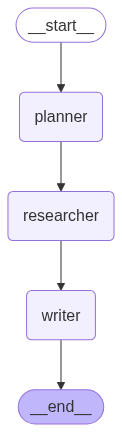

In [17]:
from IPython.display import Image
from IPython.display import display

display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
# Run Example
query = {"input": "What are the benefits and risks of using AI in education?"}

In [25]:
final_state = graph.invoke(query)
print("\nFINAL ANSWER:\n", final_state["final_output"])

PLAN CREATED:
 Of course. Here is a 3-step research plan to comprehensively answer the question.

### **Research Plan: Benefits and Risks of AI in Education**

**Objective:** To conduct a balanced investigation into the advantages and disadvantages of integrating Artificial Intelligence into educational settings, from primary schools to higher education.

---

### **Step 1: Identify and Categorize the Core Benefits and Risks**

This initial step focuses on gathering and organizing the primary arguments for and against the use of AI in education. The goal is to build a foundational understanding by mapping the landscape of existing applications and theoretical concerns.

*   **Sub-task 1.1: Research the Benefits.** Investigate how AI is currently being used to improve educational outcomes. Group findings into key categories:
    *   **Personalized Learning:** How do AI-driven platforms create adaptive learning paths for individual students? Look for case studies on systems that adjust d